In [14]:
import pandas as pd

# Carregar o dataset
df = pd.read_csv('googleplaystore.csv')

# Exibir as primeiras linhas do dataset
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
# Remover as linhas duplicadas
df = df.drop_duplicates()

# Verificar as primeiras linhas após a remoção
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


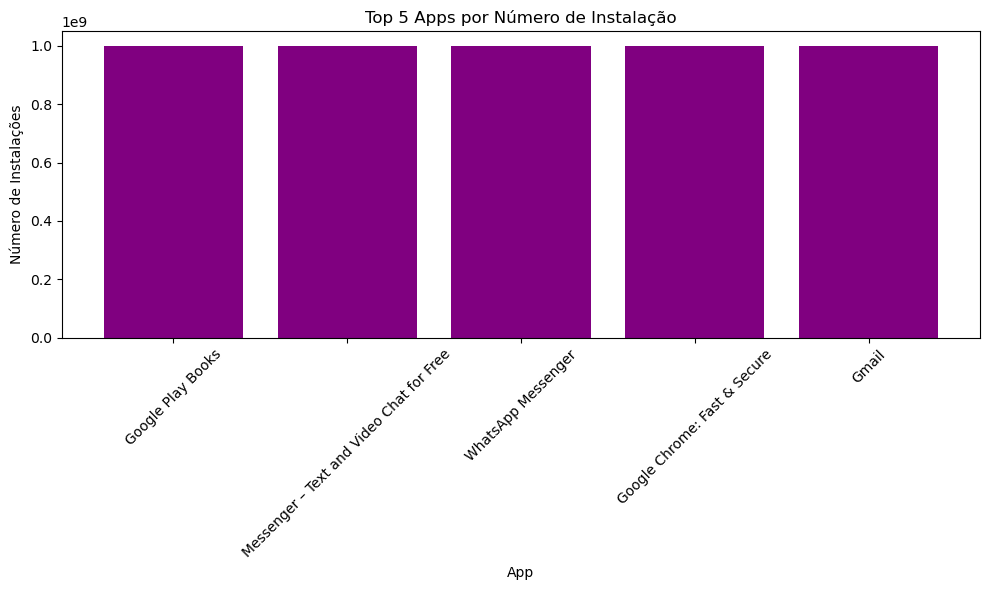

In [21]:
import matplotlib.pyplot as plt
import pandas as pd  # Adding pandas import which was likely missing

# Limpar a coluna Installs removendo os caracteres '+' e ',' e convertê-la para tipo numérico
# Replace empty strings with '0' before converting to int
df['Installs'] = df['Installs'].str.replace(r'[^\d]', '', regex=True)
df['Installs'] = df['Installs'].replace('', '0')  # Replace empty strings with '0'
df['Installs'] = df['Installs'].astype(int)  # Now safe to convert to int

# Selecionar os 5 apps com maior número de instalações
top_5_apps = df.nlargest(5, 'Installs')

# Plotar o gráfico de barras
plt.figure(figsize=(10, 6))
plt.bar(top_5_apps['App'], top_5_apps['Installs'], color='purple')
plt.title('Top 5 Apps por Número de Instalação')
plt.xlabel('App')
plt.ylabel('Número de Instalações')
plt.xticks(rotation=45)
plt.tight_layout()  # Added to prevent labels from being cut off
plt.show()

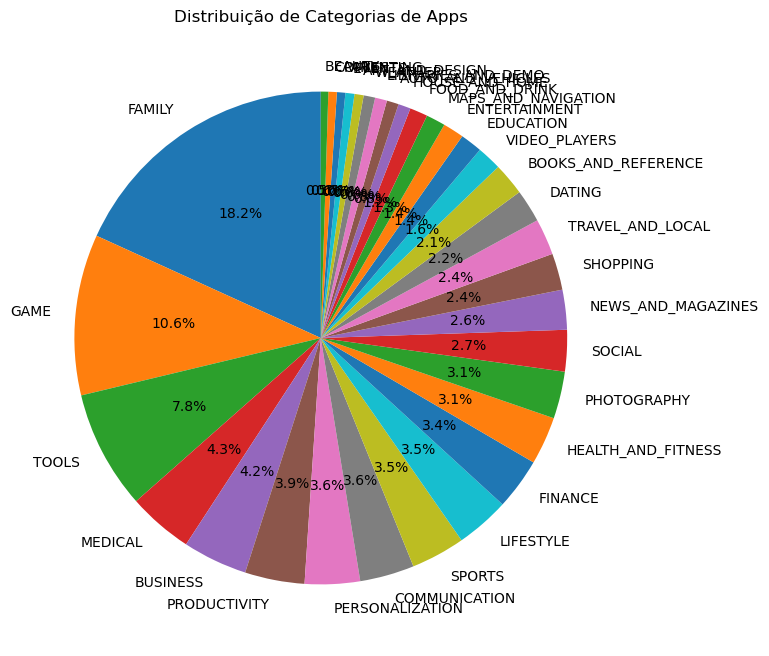

In [29]:
# Contar a frequência das categorias
category_counts = df['Category'].value_counts()

# Plotar o gráfico de pizza
plt.figure(figsize=(8, 8))
category_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('Distribuição de Categorias de Apps')
plt.ylabel('')
plt.show()


In [28]:
# Converter a coluna 'Price' para numérica, removendo o símbolo de moeda
# Add error handling to skip rows that can't be converted
df['Price'] = pd.to_numeric(df['Price'].replace('[$,]', '', regex=True), errors='coerce')

# Drop NaN values or replace them with 0 depending on your needs
df = df.dropna(subset=['Price'])  # Remove rows where Price couldn't be converted

# Encontrar o app mais caro
most_expensive_app = df.loc[df['Price'].idxmax()]

print(f'O app mais caro é: {most_expensive_app["App"]}, com o preço de {most_expensive_app["Price"]}')

O app mais caro é: I'm Rich - Trump Edition, com o preço de 400.0


In [30]:
# Contar o número de apps com a classificação 'Mature 17+'
mature_apps = df[df['Content Rating'] == 'Mature 17+']
print(f'Número de apps com classificação "Mature 17+": {mature_apps.shape[0]}')


Número de apps com classificação "Mature 17+": 499


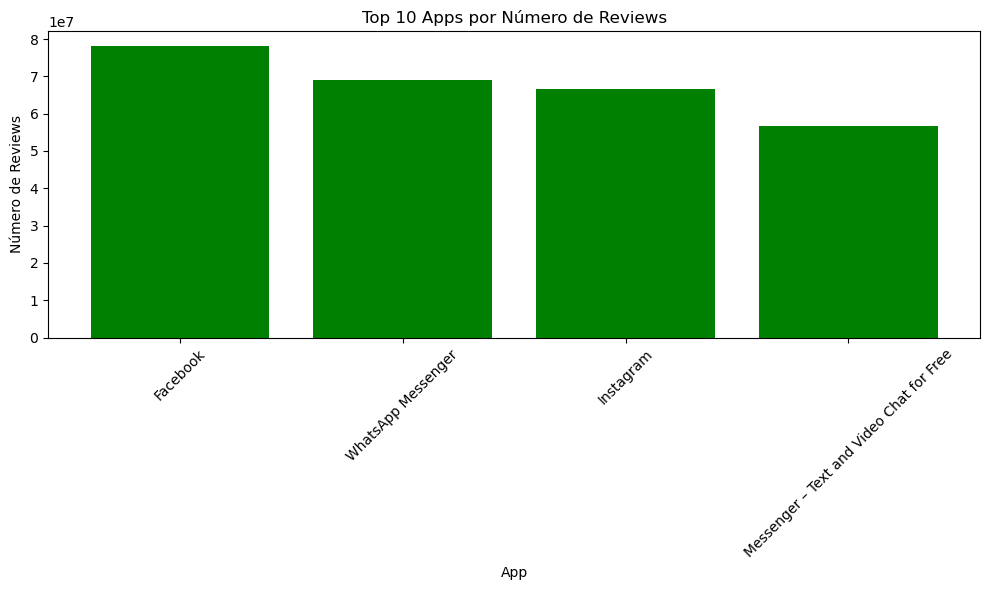

In [32]:
# Convert 'Reviews' column to numeric type
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

# Selecionar os 10 apps com mais reviews
top_10_reviews = df.nlargest(10, 'Reviews')

# Plotar o gráfico de barras
plt.figure(figsize=(10, 6))
plt.bar(top_10_reviews['App'], top_10_reviews['Reviews'], color='green')
plt.title('Top 10 Apps por Número de Reviews')
plt.xlabel('App')
plt.ylabel('Número de Reviews')
plt.xticks(rotation=45)
plt.tight_layout()  # Added to prevent label cutoff
plt.show()

In [33]:
# Calcular a média de reviews
mean_reviews = df['Reviews'].mean()

# Calcular o preço médio dos apps
mean_price = df['Price'].mean()

print(f'Média de Reviews: {mean_reviews}')
print(f'Preço Médio dos Apps: {mean_price}')


Média de Reviews: 444152.89603321033
Preço Médio dos Apps: 1.027368081180812


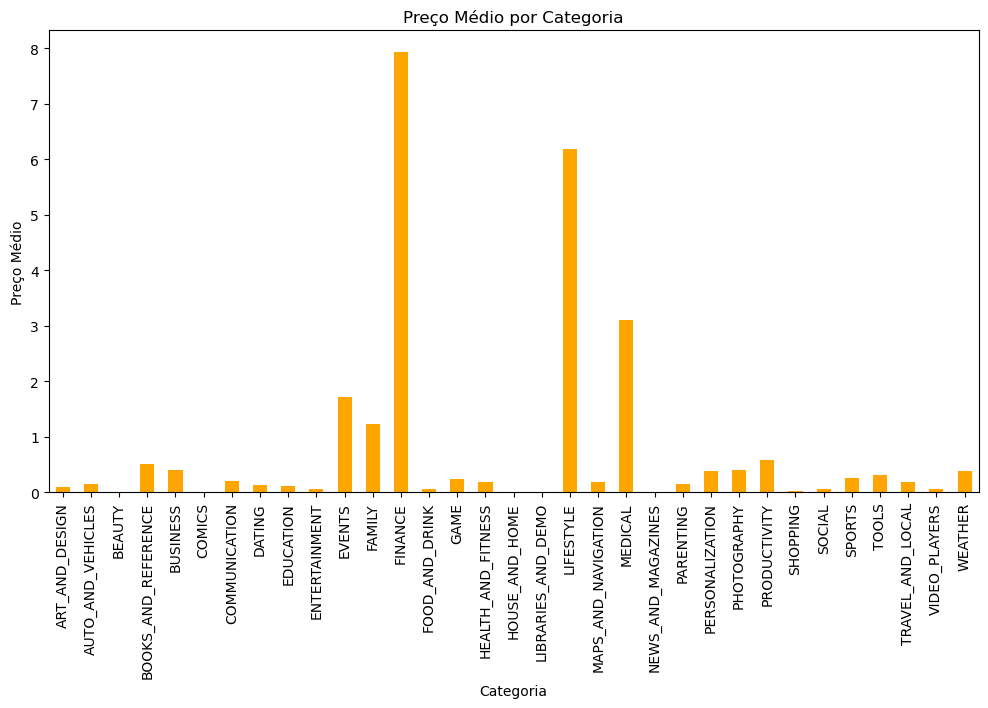

In [34]:
# Calcular o preço médio por categoria
category_price = df.groupby('Category')['Price'].mean()

# Plotar o gráfico de barras
category_price.plot(kind='bar', figsize=(12, 6), color='orange')
plt.title('Preço Médio por Categoria')
plt.ylabel('Preço Médio')
plt.xlabel('Categoria')
plt.xticks(rotation=90)
plt.show()


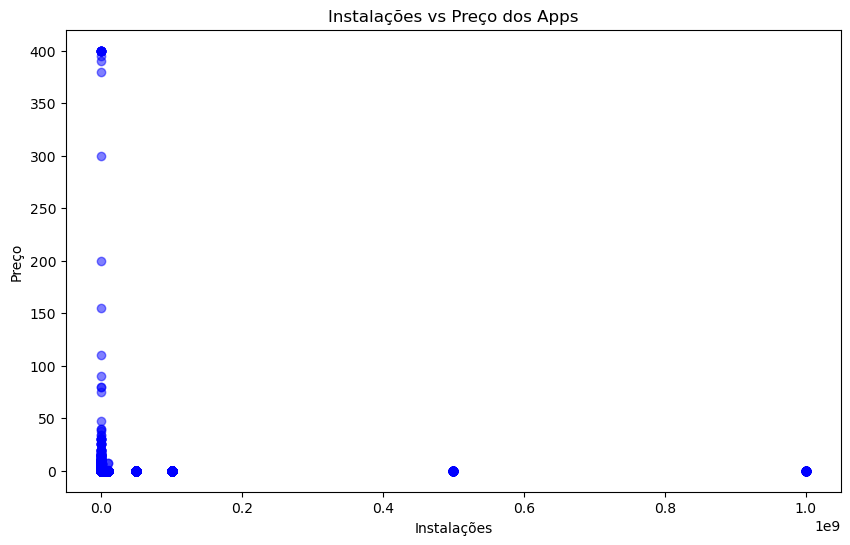

In [35]:
# Gráfico de dispersão entre Instalações e Preço
plt.figure(figsize=(10, 6))
plt.scatter(df['Installs'], df['Price'], alpha=0.5, color='blue')
plt.title('Instalações vs Preço dos Apps')
plt.xlabel('Instalações')
plt.ylabel('Preço')
plt.show()
